In [6]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from beta_evidence_field import (OccupancyField, OccupancyObservation)
from tools.plotting      import configure_plots, plot_evidence_2d, plot_query_2d

configure_plots()

In [7]:
SPATIAL_DIMENSIONS = (-4.0, -4.0, 4.0, 4.0)
SPATIAL_RESOLUTION = 100

ANGLE_RESOLUTION   = 90
ANGLE_OFFSET       = np.deg2rad(45)
ANGLE_RANGE        = (-np.pi/2, np.pi)

OBSERVATION_RANGE  = 3.0

In [8]:
field        = OccupancyField.from_yaml("../config/example_2d_config.yaml")
observations = []

observation = OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                   direction = np.array([np.cos(ANGLE_OFFSET), np.sin(ANGLE_OFFSET)]),
                                   range     = OBSERVATION_RANGE,
                                   returned  = True,
                                   time      = 0.0)

for angle in tqdm(np.linspace(ANGLE_RANGE[0], ANGLE_RANGE[1], ANGLE_RESOLUTION, endpoint=False), desc = "Generating observations"):
    observations.append(OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                             direction = np.array([np.cos(angle + ANGLE_OFFSET), np.sin(angle + ANGLE_OFFSET)]),
                                             range     = OBSERVATION_RANGE,
                                             returned  = True,
                                             time      = 0.0))

field.clear()
obs = field.add(observations)

Generating observations:   0%|          | 0/90 [00:00<?, ?it/s]

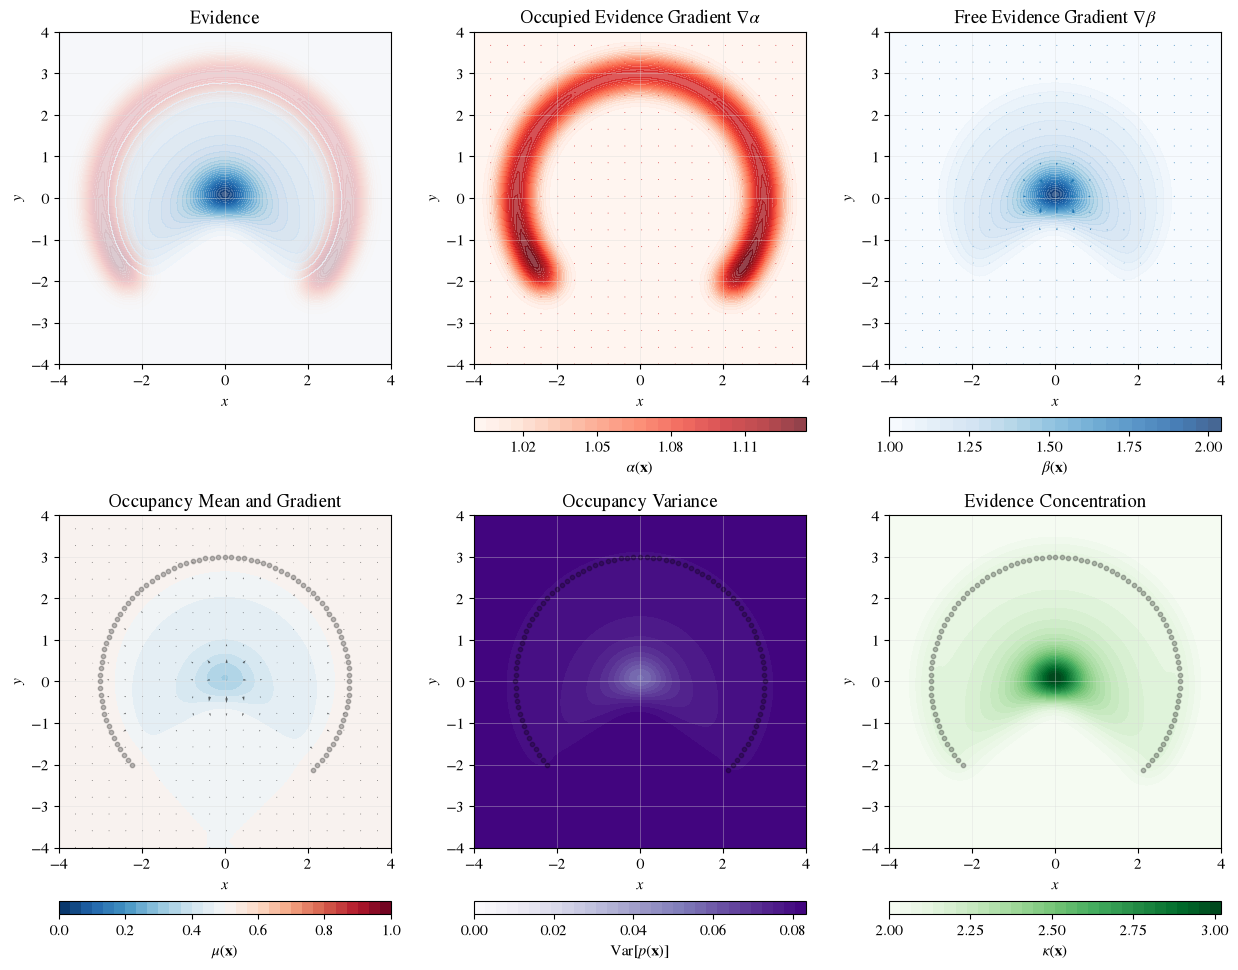

In [9]:
x = np.linspace(SPATIAL_DIMENSIONS[0], SPATIAL_DIMENSIONS[2], SPATIAL_RESOLUTION)
y = np.linspace(SPATIAL_DIMENSIONS[1], SPATIAL_DIMENSIONS[3], SPATIAL_RESOLUTION)

X, Y = np.meshgrid(x, y, indexing = "ij")

fig, axes = plt.subplots(2, 3, figsize = (15, 11))
fig.subplots_adjust(hspace = 0.33, wspace = 0.25)

plot_evidence_2d(X     = X,
                 Y     = Y,
                 field = field,
                 axes  = axes[0])

plot_query_2d(X     = X,
              Y     = Y,
              field = field,
              axes  = axes[1])

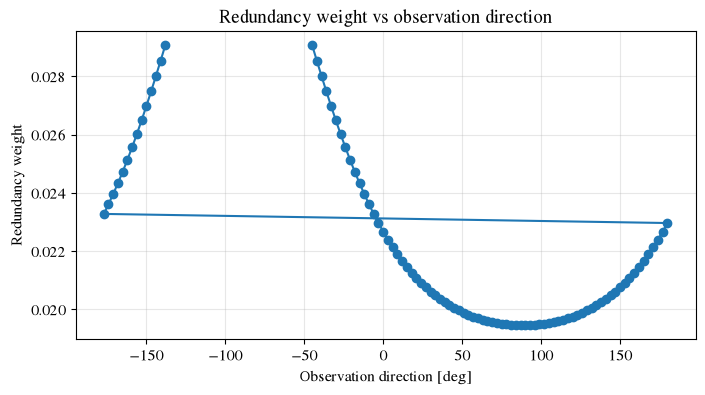

In [10]:
observations = field.observations

angles = np.rad2deg([
    np.arctan2(observation.direction[1],
               observation.direction[0])
    for observation in observations
])

weights = field._redundancy

fig, ax = plt.subplots(figsize = (8, 4))

ax.plot(angles,
        weights,
        "o-")

ax.set_xlabel("Observation direction [deg]")
ax.set_ylabel("Redundancy weight")
ax.set_title("Redundancy weight vs observation direction")
ax.grid(alpha = 0.3)

plt.show()